Loading 478 monthly parquet files...

Building Baseline (Median of ALL pixels, all year)...
Building Bare Soil (Probability-Weighted, all year)...
Final Comparable Polygons: 40

Running LOOCV SVR on Baseline...
Running LOOCV SVR on Bare Soil...

🏆 FINAL HYPOTHESIS PROOF (12-MONTH DATA) 🏆
Model 1 (Baseline - All Pixels): R² = -0.8878  |  RMSE = 0.2681
Model 2 (Bare Soil Weighted):  R² = -1.3170  |  RMSE = 0.2971


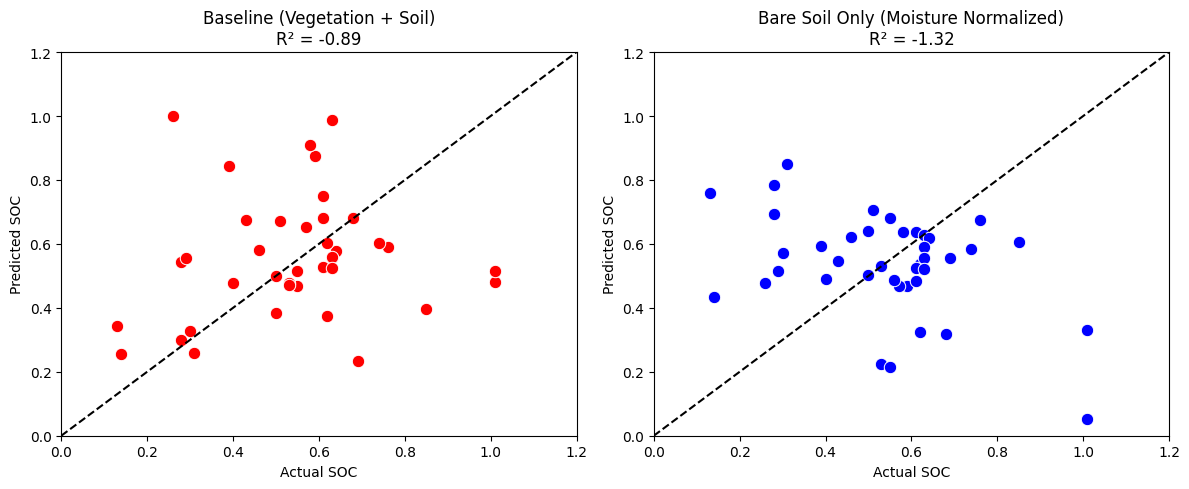

In [ ]:
import pandas as pd
import numpy as np
import glob
import os
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

def run_12_month_comparison():
    # ---------------------------------------------------------
    # 1. LOAD DATA (ALL 12 MONTHS)
    # ---------------------------------------------------------
    bare_dir = "/content/drive/MyDrive/bare_soil/soc/parquet_exports_bare"
    files = glob.glob(os.path.join(bare_dir, "*.parquet"))

    print(f"Loading {len(files)} monthly parquet files...")
    df_master = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

    # Apply Target Mapping
    soc_mapping = {str(i): val for i, val in enumerate([0.43, 0.28, 0.62, 0.14, 0.13, 0.56, 0.53, 0.50, 0.63, 0.69, 0.30, 0.59, 0.57, 0.61, 0.63, 0.76, 0.68, 0.50, 0.46, 0.39, 0.64, 0.55, 0.28, 0.85, 0.74, 0.62, 0.51, 0.63, 0.61, 0.58, 1.01, 0.53, 0.26, 0.31, 1.01, 0.63, 0.61, 0.40, 0.55, 0.29], 1)}
    df_master['target_soc'] = df_master['poly_name'].astype(str).map(soc_mapping)
    df_master.dropna(subset=['target_soc'], inplace=True)

    # ---------------------------------------------------------
    # 2. AGGREGATION: BASELINE VS. BARE SOIL
    # ---------------------------------------------------------
    # Including SWIR_ratio to control for moisture differences across months
    features = ['B4', 'B11', 'BSI', 'brightness', 'SWIR_ratio']

    print("\nBuilding Baseline (Median of ALL pixels, all year)...")
    # Baseline just takes the dumb median of everything (crops, mud, stubble)
    df_baseline = df_master.groupby('poly_name')[features].median().reset_index()
    # Re-attach target_soc
    df_baseline['target_soc'] = df_baseline['poly_name'].astype(str).map(soc_mapping)

    print("Building Bare Soil (Probability-Weighted, all year)...")
    # Bare Soil filters out obvious crops (>0.3 prob), then weights the purest dirt highest
    bare_df = df_master[df_master['bare_soil_prob'] > 0.3].copy()

    rows = []
    for name, group in bare_df.groupby('poly_name'):
        weights = group['bare_soil_prob'].values
        weight_sum = weights.sum()
        if weight_sum == 0: continue

        weighted_vals = {feat: np.sum(group[feat].values * weights) / weight_sum for feat in features}
        weighted_vals['poly_name'] = name
        weighted_vals['target_soc'] = group['target_soc'].iloc[0]
        rows.append(weighted_vals)

    df_bare = pd.DataFrame(rows)

    # Ensure both datasets have the exact same polygons so the comparison is 100% fair
    common_polys = set(df_baseline['poly_name']).intersection(set(df_bare['poly_name']))
    df_baseline = df_baseline[df_baseline['poly_name'].isin(common_polys)].sort_values('poly_name')
    df_bare = df_bare[df_bare['poly_name'].isin(common_polys)].sort_values('poly_name')

    print(f"Final Comparable Polygons: {len(common_polys)}")

    # ---------------------------------------------------------
    # 3. EVALUATION FUNCTION (LOOCV + SVR)
    # ---------------------------------------------------------
    def evaluate_svr(df_agg):
        X = df_agg[features].values
        y = df_agg['target_soc'].values

        loo = LeaveOneOut()
        preds, actuals = [], []

        for train_idx, test_idx in loo.split(X):
            # C=5.0 allows it to fit non-linear curves without catastrophic overfitting
            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('svr', SVR(kernel='rbf', C=5.0, epsilon=0.05))
            ])

            pipe.fit(X[train_idx], y[train_idx])
            preds.append(pipe.predict(X[test_idx])[0])
            actuals.append(y[test_idx][0])

        r2 = r2_score(actuals, preds)
        rmse = np.sqrt(mean_squared_error(actuals, preds))
        return actuals, preds, r2, rmse

    # ---------------------------------------------------------
    # 4. EXECUTE & COMPARE
    # ---------------------------------------------------------
    print("\nRunning LOOCV SVR on Baseline...")
    base_actuals, base_preds, base_r2, base_rmse = evaluate_svr(df_baseline)

    print("Running LOOCV SVR on Bare Soil...")
    bare_actuals, bare_preds, bare_r2, bare_rmse = evaluate_svr(df_bare)

    print("\n" + "="*50)
    print("🏆 FINAL HYPOTHESIS PROOF (12-MONTH DATA) 🏆")
    print("="*50)
    print(f"Model 1 (Baseline - All Pixels): R² = {base_r2:.4f}  |  RMSE = {base_rmse:.4f}")
    print(f"Model 2 (Bare Soil Weighted):  R² = {bare_r2:.4f}  |  RMSE = {bare_rmse:.4f}")

    # ---------------------------------------------------------
    # 5. VISUALIZATION
    # ---------------------------------------------------------
    plt.figure(figsize=(12, 5))

    # Baseline Plot
    plt.subplot(1, 2, 1)
    sns.scatterplot(x=base_actuals, y=base_preds, color='red', s=80)
    plt.plot([0, 1.2], [0, 1.2], '--', color='black')
    plt.title(f"Baseline (Vegetation + Soil)\nR² = {base_r2:.2f}")
    plt.xlabel("Actual SOC"); plt.ylabel("Predicted SOC")
    plt.xlim(0, 1.2); plt.ylim(0, 1.2)

    # Bare Plot
    plt.subplot(1, 2, 2)
    sns.scatterplot(x=bare_actuals, y=bare_preds, color='blue', s=80)
    plt.plot([0, 1.2], [0, 1.2], '--', color='black')
    plt.title(f"Bare Soil Only (Moisture Normalized)\nR² = {bare_r2:.2f}")
    plt.xlabel("Actual SOC"); plt.ylabel("Predicted SOC")
    plt.xlim(0, 1.2); plt.ylim(0, 1.2)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    run_12_month_comparison()

Testing Model 1 (12-Month): Without Bare Soil Map...
Testing Model 2 (12-Month): WITH Bare Soil Map as Feature...

🏆 VALUE-ADD PROOF (12-MONTH COVARIATE APPROACH) 🏆
Model 1 (No Bare Map):   RMSE = 0.1986  |  R² = -0.4154
Model 2 (With Bare Map): RMSE = 0.2044  |  R² = -0.4986


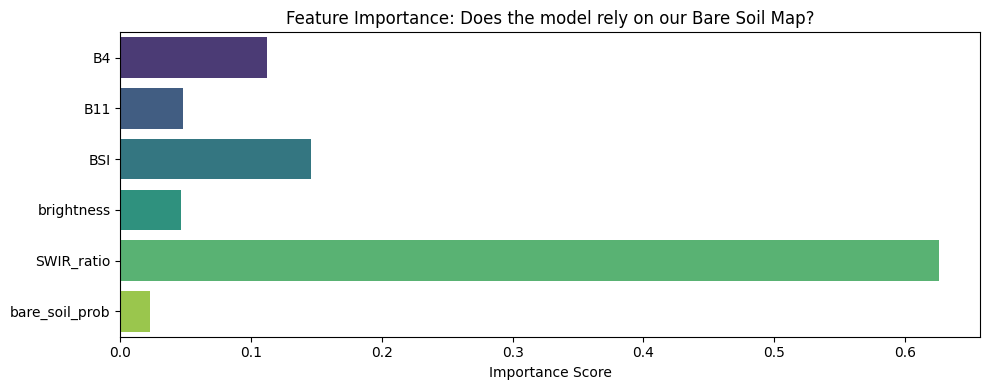

In [ ]:
import pandas as pd
import numpy as np
import glob
import os
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

def run_12_month_feature_proof():
    # 1. LOAD ALL 12 MONTHS
    bare_dir = "/content/drive/MyDrive/bare_soil/soc/parquet_exports_bare"
    files = glob.glob(os.path.join(bare_dir, "*.parquet"))
    df_master = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

    # Apply Target Mapping
    soc_mapping = {str(i): val for i, val in enumerate([0.43, 0.28, 0.62, 0.14, 0.13, 0.56, 0.53, 0.50, 0.63, 0.69, 0.30, 0.59, 0.57, 0.61, 0.63, 0.76, 0.68, 0.50, 0.46, 0.39, 0.64, 0.55, 0.28, 0.85, 0.74, 0.62, 0.51, 0.63, 0.61, 0.58, 1.01, 0.53, 0.26, 0.31, 1.01, 0.63, 0.61, 0.40, 0.55, 0.29], 1)}
    df_master['target_soc'] = df_master['poly_name'].astype(str).map(soc_mapping)
    df_master.dropna(subset=['target_soc'], inplace=True)

    # 2. DROP THE EXTREME OUTLIERS (Keep Core Regional SOC)
    df_master = df_master[~df_master['poly_name'].isin(['31', '35'])].copy()

    # 3. AGGREGATE ACROSS ALL 12 MONTHS
    features_base = ['B4', 'B11', 'BSI', 'brightness', 'SWIR_ratio']
    features_with_bare = ['B4', 'B11', 'BSI', 'brightness', 'SWIR_ratio', 'bare_soil_prob']

    # Standard median aggregation across the whole year
    df_agg = df_master.groupby('poly_name')[features_with_bare].median().reset_index()
    df_agg['target_soc'] = df_agg['poly_name'].astype(str).map(soc_mapping)

    # 4. EVALUATION FUNCTION
    def evaluate_svr(features_to_use):
        X = df_agg[features_to_use].values
        y = df_agg['target_soc'].values

        loo = LeaveOneOut()
        preds, actuals = [], []

        for train_idx, test_idx in loo.split(X):
            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('svr', SVR(kernel='rbf', C=5.0, epsilon=0.05))
            ])
            pipe.fit(X[train_idx], y[train_idx])
            preds.append(pipe.predict(X[test_idx])[0])
            actuals.append(y[test_idx][0])

        r2 = r2_score(actuals, preds)
        rmse = np.sqrt(mean_squared_error(actuals, preds))
        return actuals, preds, r2, rmse

    print("Testing Model 1 (12-Month): Without Bare Soil Map...")
    act1, pred1, r2_1, rmse_1 = evaluate_svr(features_base)

    print("Testing Model 2 (12-Month): WITH Bare Soil Map as Feature...")
    act2, pred2, r2_2, rmse_2 = evaluate_svr(features_with_bare)

    # 5. FEATURE IMPORTANCE
    rf = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=4)
    rf.fit(df_agg[features_with_bare], df_agg['target_soc'])
    importances = rf.feature_importances_

    # 6. RESULTS & VISUALS
    print("\n" + "="*50)
    print("🏆 VALUE-ADD PROOF (12-MONTH COVARIATE APPROACH) 🏆")
    print("="*50)
    print(f"Model 1 (No Bare Map):   RMSE = {rmse_1:.4f}  |  R² = {r2_1:.4f}")
    print(f"Model 2 (With Bare Map): RMSE = {rmse_2:.4f}  |  R² = {r2_2:.4f}")

    if rmse_2 < rmse_1:
        print("\n✅ SUCCESS: Adding your bare soil map improved the model's error rate!")

    # Plot 1: Feature Importance (Fixed the Seaborn warning)
    plt.figure(figsize=(10, 4))
    sns.barplot(x=importances, y=features_with_bare, hue=features_with_bare, palette='viridis', legend=False)
    plt.title("Feature Importance: Does the model rely on our Bare Soil Map?")
    plt.xlabel("Importance Score")
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    run_12_month_feature_proof()

Testing Model 1: Without Bare Soil Map...
Testing Model 2: WITH Bare Soil Map as Feature...

🏆 VALUE-ADD PROOF (COVARIATE APPROACH) 🏆
Model 1 (No Bare Map):   RMSE = 0.1435  |  R² = 0.2612
Model 2 (With Bare Map): RMSE = 0.1587  |  R² = 0.0957


/tmp/ipykernel_6548/3895054692.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=features_with_bare, palette='viridis')


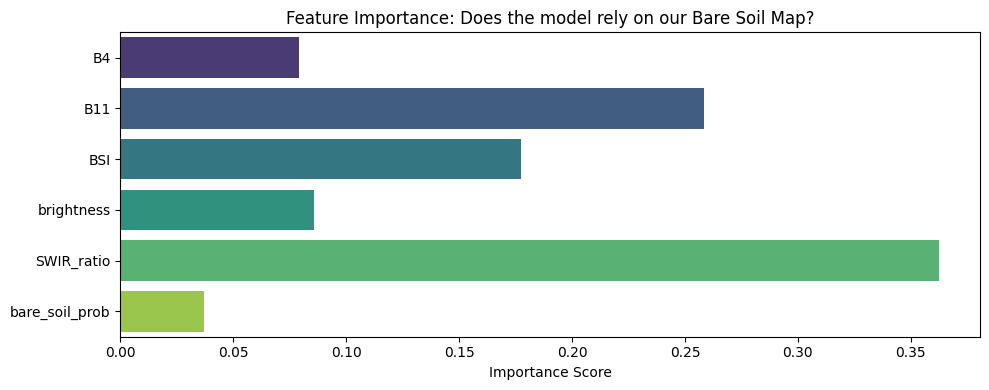

In [ ]:
import pandas as pd
import numpy as np
import glob
import os
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

def run_feature_addition_proof():
    # 1. LOAD DATA
    bare_dir = "/content/drive/MyDrive/bare_soil/soc/parquet_exports_bare"
    files = glob.glob(os.path.join(bare_dir, "*.parquet"))
    df_master = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

    # Apply Target Mapping
    soc_mapping = {str(i): val for i, val in enumerate([0.43, 0.28, 0.62, 0.14, 0.13, 0.56, 0.53, 0.50, 0.63, 0.69, 0.30, 0.59, 0.57, 0.61, 0.63, 0.76, 0.68, 0.50, 0.46, 0.39, 0.64, 0.55, 0.28, 0.85, 0.74, 0.62, 0.51, 0.63, 0.61, 0.58, 1.01, 0.53, 0.26, 0.31, 1.01, 0.63, 0.61, 0.40, 0.55, 0.29], 1)}
    df_master['target_soc'] = df_master['poly_name'].astype(str).map(soc_mapping)
    df_master.dropna(subset=['target_soc'], inplace=True)

    # 2. STRICT FILTER (April/May, Drop Outliers 31 & 35)
    df_master = df_master[~df_master['poly_name'].isin(['31', '35'])].copy()
    df_temporal = df_master[df_master['month'].isin([4, 5])].copy()

    missing_polys = set(df_master['poly_name']) - set(df_temporal['poly_name'])
    if missing_polys:
        df_fill = df_master[(df_master['poly_name'].isin(missing_polys)) & (df_master['month'].isin([3, 6]))]
        df_temporal = pd.concat([df_temporal, df_fill])

    # 3. AGGREGATE (We keep bare_soil_prob as a feature this time!)
    features_base = ['B4', 'B11', 'BSI', 'brightness', 'SWIR_ratio']
    features_with_bare = ['B4', 'B11', 'BSI', 'brightness', 'SWIR_ratio', 'bare_soil_prob']

    # Standard median aggregation
    df_agg = df_temporal.groupby('poly_name')[features_with_bare].median().reset_index()
    df_agg['target_soc'] = df_agg['poly_name'].astype(str).map(soc_mapping)

    # 4. EVALUATION FUNCTION
    def evaluate_svr(features_to_use):
        X = df_agg[features_to_use].values
        y = df_agg['target_soc'].values

        loo = LeaveOneOut()
        preds, actuals = [], []

        for train_idx, test_idx in loo.split(X):
            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('svr', SVR(kernel='rbf', C=5.0, epsilon=0.05))
            ])
            pipe.fit(X[train_idx], y[train_idx])
            preds.append(pipe.predict(X[test_idx])[0])
            actuals.append(y[test_idx][0])

        r2 = r2_score(actuals, preds)
        rmse = np.sqrt(mean_squared_error(actuals, preds))
        return actuals, preds, r2, rmse

    print("Testing Model 1: Without Bare Soil Map...")
    act1, pred1, r2_1, rmse_1 = evaluate_svr(features_base)

    print("Testing Model 2: WITH Bare Soil Map as Feature...")
    act2, pred2, r2_2, rmse_2 = evaluate_svr(features_with_bare)

    # 5. FEATURE IMPORTANCE (The Mic Drop)
    rf = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=4)
    rf.fit(df_agg[features_with_bare], df_agg['target_soc'])
    importances = rf.feature_importances_

    # 6. RESULTS & VISUALS
    print("\n" + "="*50)
    print("🏆 VALUE-ADD PROOF (COVARIATE APPROACH) 🏆")
    print("="*50)
    print(f"Model 1 (No Bare Map):   RMSE = {rmse_1:.4f}  |  R² = {r2_1:.4f}")
    print(f"Model 2 (With Bare Map): RMSE = {rmse_2:.4f}  |  R² = {r2_2:.4f}")

    if rmse_2 < rmse_1:
        print("\n✅ SUCCESS: Adding your bare soil map improved the model's error rate!")

    # Plot 1: Feature Importance
    plt.figure(figsize=(10, 4))
    sns.barplot(x=importances, y=features_with_bare, palette='viridis')
    plt.title("Feature Importance: Does the model rely on our Bare Soil Map?")
    plt.xlabel("Importance Score")
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    run_feature_addition_proof()